# Arithmetic, Bitwise Operations and Masking

Masks - single-channel images where white means 'work here' and black means 'ignore' - are everywhere in OpenCV. This notebook covers the arithmetic and bitwise operations that create and use masks: adding and blending images, AND/OR/XOR/NOT, masking, and region-based processing.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Adding images and saturation arithmetic

`cv2.add` saturates at 255 (correct for images), while plain NumPy addition wraps around modulo 256 and creates wrong colours. Blending with weights is done by `cv2.addWeighted`.

cv2.add result: [255 255 255]  (saturates at 255)
numpy + result: [44 44 44]  (wraps: 300 % 256 = 44)


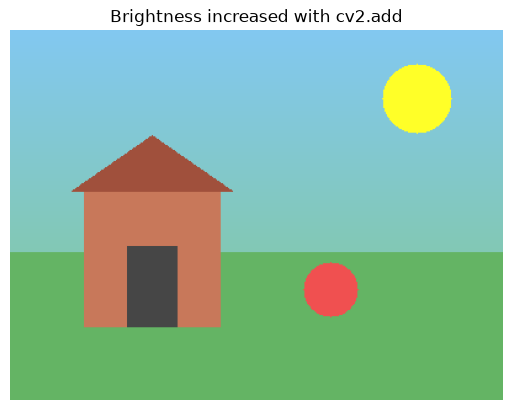

In [2]:
a = np.full((100, 100, 3), 200, np.uint8)
b = np.full((100, 100, 3), 100, np.uint8)
print("cv2.add result:", cv2.add(a, b)[0, 0], " (saturates at 255)")
print("numpy + result:", (a + b)[0, 0], " (wraps: 300 % 256 = 44)")
img = cv2.imread("../assets/test_image.png")
brighter = cv2.add(img, np.full(img.shape, 40, np.uint8))
show(brighter, "Brightness increased with cv2.add")

## Bitwise AND, OR, XOR and NOT

Bitwise operations combine images pixel by pixel at the bit level. On binary masks they behave like set operations: AND = intersection, OR = union, XOR = difference, NOT = inverse. With a mask argument, an operation only applies where the mask is white.

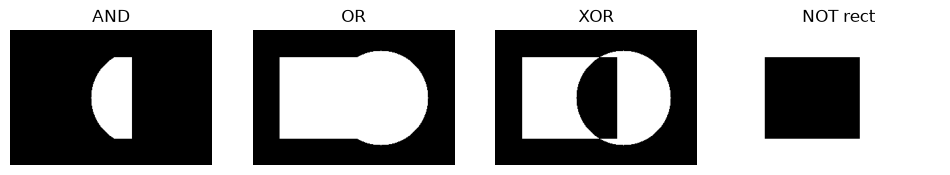

In [3]:
h, w = 200, 300
rect = np.zeros((h, w), np.uint8); cv2.rectangle(rect, (40, 40), (180, 160), 255, -1)
circ = np.zeros((h, w), np.uint8); cv2.circle(circ, (190, 100), 70, 255, -1)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, m, name in zip(axes, (cv2.bitwise_and(rect, circ), cv2.bitwise_or(rect, circ),
                              cv2.bitwise_xor(rect, circ), cv2.bitwise_not(rect)),
                       ("AND", "OR", "XOR", "NOT rect")):
    ax.imshow(m, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.show()

## Masking: keeping only a region

The standard pattern: build a mask, then `cv2.bitwise_and(img, img, mask=mask)` keeps the original pixels where the mask is white and black elsewhere. This extracts objects, logos, lanes, skin regions - anything you can describe as a mask.

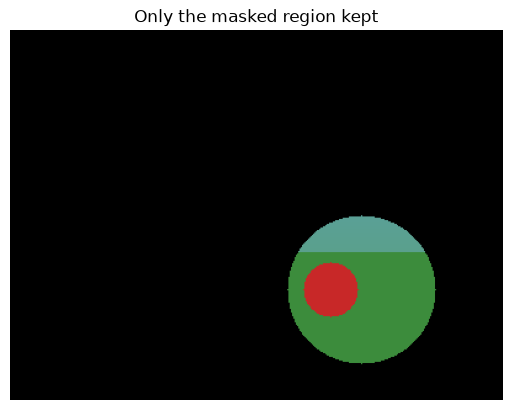

Kept pixels: 11289 of 120000


In [4]:
img = cv2.imread("../assets/test_image.png")
mask = np.zeros(img.shape[:2], np.uint8)
cv2.circle(mask, (285, 210), 60, 255, -1)   # around the red ball area
extracted = cv2.bitwise_and(img, img, mask=mask)
show(extracted, "Only the masked region kept")
print("Kept pixels:", int((mask > 0).sum()), "of", mask.size)

## Combining a foreground onto a new background

The logo-on-photo recipe: threshold the foreground to get a mask, invert it, take the background through the inverse mask, take the foreground through the mask, and add. This is the classic compositing pipeline.

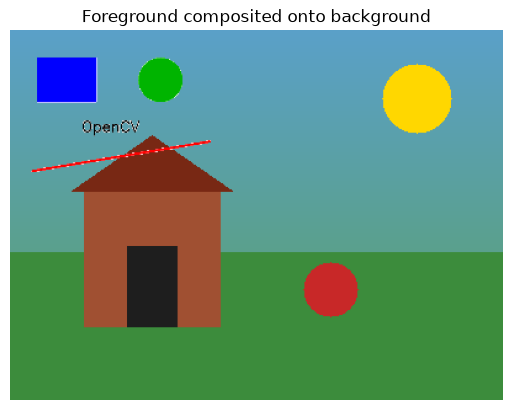

In [5]:
bg = cv2.imread("../assets/test_image.png")
fg = cv2.imread("../assets/shapes.png")
fg_small = cv2.resize(fg, (160, 120))
roi = bg[10:130, 10:170]
fg_gray = cv2.cvtColor(fg_small, cv2.COLOR_BGR2GRAY)
_, fg_mask = cv2.threshold(fg_gray, 240, 255, cv2.THRESH_BINARY_INV)
bg_part = cv2.bitwise_and(roi, roi, mask=cv2.bitwise_not(fg_mask))
fg_part = cv2.bitwise_and(fg_small, fg_small, mask=fg_mask)
bg[10:130, 10:170] = cv2.add(bg_part, fg_part)
show(bg, "Foreground composited onto background")

## Masked statistics and histograms

Masks also restrict measurements: `cv2.mean` with a mask averages only masked pixels, and `cv2.calcHist` accepts a mask too. This is how you measure 'the average colour of the detected object' rather than of the whole frame.

In [6]:
ball_mask = np.zeros(img.shape[:2], np.uint8)
cv2.circle(ball_mask, (285, 210), 45, 255, -1)
mean_bgr = cv2.mean(img, mask=ball_mask)[:3]
print("Mean BGR inside the ball mask:", tuple(round(v, 1) for v in mean_bgr))
hist = cv2.calcHist([img], [2], ball_mask, [256], [0, 256])
print("Masked red-channel histogram peak at intensity:", int(np.argmax(hist)))

Mean BGR inside the ball mask: (63.9, 118.8, 95.7)
Masked red-channel histogram peak at intensity: 60


## Creating masks from shapes and ranges - recap

Masks come from three main sources: drawn shapes (this notebook), colour ranges with inRange (notebook 04), and thresholding (notebook 07). Once you think in masks, most OpenCV pipelines become: build mask -> clean mask -> measure or extract with mask.

Bright pixels inside the rectangle: 0


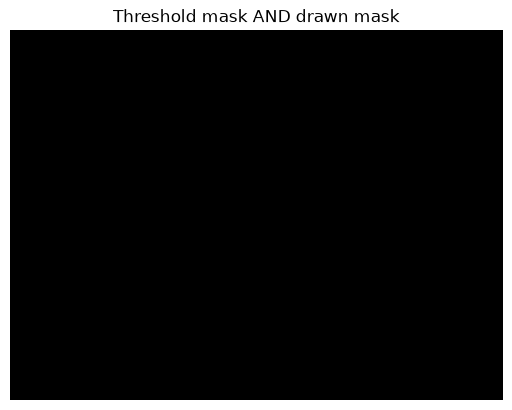

In [7]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, thresh_mask = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY)
drawn = np.zeros_like(gray); cv2.rectangle(drawn, (50, 120), (180, 250), 255, -1)
combined = cv2.bitwise_and(thresh_mask, drawn)
print("Bright pixels inside the rectangle:", int((combined > 0).sum()))
show(combined, "Threshold mask AND drawn mask")

## Key Points

- cv2.add saturates at 255; NumPy + wraps around - use cv2.add for images.
- On masks: AND = intersection, OR = union, XOR = difference, NOT = inverse.
- bitwise_and(img, img, mask=mask) is the standard region-extraction pattern.
- Compositing = foreground through mask + background through inverse mask, then add.
- Masks restrict measurements too: cv2.mean and calcHist both accept a mask.

## Mini Task

1. Create a circular mask on `shapes.png` and extract only that region.
2. Invert the mask and extract the opposite region; verify the two pixel counts add up to the full image.
3. Composite `template.png` (resized) onto a corner of `test_image.png` using the mask recipe.